In [29]:
#to read our files
import pandas as pd
import numpy as np
df =pd.read_csv("ipl_data.csv")
print(df.head())

  Match_ID      Venue Pitch_Type Toss_Decision Innings  Overs_Faced  \
0  IPL1119  Bengaluru   Balanced           Bat     1st         15.9   
1  IPL1223      Delhi    Bowling           Bat     1st          NaN   
2  IPL1199     Mumbai   Balanced         Field     1st         18.5   
3  IPL1102      Delhi   Balanced           Bat     2nd         14.3   
4  IPL1103      Delhi    Batting         Field     2nd         17.5   

   Boundaries  Wickets_Lost  Extras  Match_Date  Total_Runs  
0          23             9    12.0  2026-09-21         184  
1          23             5     8.0  2024-12-09         186  
2          17             8    10.0  2025-02-12         190  
3          21             8    11.0  2026-07-08         166  
4          10             4    16.0  2026-07-18         179  


In [30]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns)

print("\nDataset Information:")
df.info()

print("\nFirst 5 Rows:")
print(df.head())

print("\nMissing Values:")
print(df.isnull().sum())

Dataset Shape: (255, 11)

Column Names:
Index(['Match_ID', 'Venue', 'Pitch_Type', 'Toss_Decision', 'Innings',
       'Overs_Faced', 'Boundaries', 'Wickets_Lost', 'Extras', 'Match_Date',
       'Total_Runs'],
      dtype='str')

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 255 entries, 0 to 254
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Match_ID       255 non-null    str    
 1   Venue          250 non-null    str    
 2   Pitch_Type     251 non-null    str    
 3   Toss_Decision  255 non-null    str    
 4   Innings        255 non-null    str    
 5   Overs_Faced    250 non-null    float64
 6   Boundaries     255 non-null    int64  
 7   Wickets_Lost   255 non-null    int64  
 8   Extras         249 non-null    float64
 9   Match_Date     255 non-null    str    
 10  Total_Runs     255 non-null    int64  
dtypes: float64(2), int64(3), str(6)
memory usage: 22.0 KB

First 5 Rows:
  Match_ID 

In [31]:
df["Overs_Faced"] = df["Overs_Faced"].fillna(df["Overs_Faced"].mean())

df["Boundaries"] = df["Boundaries"].fillna(df["Boundaries"].mean())

df["Wickets_Lost"] = df["Wickets_Lost"].fillna(df["Wickets_Lost"].mean())

df["Extras"] = df["Extras"].fillna(df["Extras"].mean())

df["Venue"] = df["Venue"].fillna(df["Venue"].mode()[0])

df["Pitch_Type"] = df["Pitch_Type"].fillna(df["Pitch_Type"].mode()[0])

df["Toss_Decision"] = df["Toss_Decision"].fillna(df["Toss_Decision"].mode()[0])

print("Missing Values After Cleaning:")
print(df.isnull().sum())

Missing Values After Cleaning:
Match_ID         0
Venue            0
Pitch_Type       0
Toss_Decision    0
Innings          0
Overs_Faced      0
Boundaries       0
Wickets_Lost     0
Extras           0
Match_Date       0
Total_Runs       0
dtype: int64


In [32]:
average_score = np.mean(df["Total_Runs"])

print("Average Total Score:", average_score)

Average Total Score: 175.40392156862745


In [33]:
highest_score = np.max(df["Total_Runs"])

lowest_score = np.min(df["Total_Runs"])

print("Highest Score:", highest_score)
print("Lowest Score:", lowest_score)

Highest Score: 218
Lowest Score: 136


In [34]:
print(df["Total_Runs"].describe())

count    255.000000
mean     175.403922
std       13.743917
min      136.000000
25%      166.000000
50%      176.000000
75%      184.000000
max      218.000000
Name: Total_Runs, dtype: float64


In [35]:
print("Scores below 150:")
print(len(df[df["Total_Runs"] < 150]))

print("\nScores between 150 and 179:")
print(len(df[(df["Total_Runs"] >= 150) & (df["Total_Runs"] < 180)]))

print("\nScores between 180 and 199:")
print(len(df[(df["Total_Runs"] >= 180) & (df["Total_Runs"] < 200)]))

print("\nScores 200 and above:")
print(len(df[df["Total_Runs"] >= 200]))

Scores below 150:
8

Scores between 150 and 179:
155

Scores between 180 and 199:
80

Scores 200 and above:
12


In [36]:
correlation = np.corrcoef(
    df["Overs_Faced"],
    df["Total_Runs"]
)[0, 1]

print("Correlation between Overs and Runs:", correlation)

Correlation between Overs and Runs: 0.4853329060351507


In [37]:
boundary_corr = np.corrcoef(
    df["Boundaries"],
    df["Total_Runs"]
)[0, 1]

print("Correlation between Boundaries and Runs:", boundary_corr)

Correlation between Boundaries and Runs: 0.5013168300132992


In [38]:
corr = df[[
    "Overs_Faced",
    "Boundaries",
    "Wickets_Lost",
    "Extras",
    "Total_Runs"
]].corr()

print(corr)

              Overs_Faced  Boundaries  Wickets_Lost    Extras  Total_Runs
Overs_Faced      1.000000    0.023580     -0.040971 -0.056244    0.485333
Boundaries       0.023580    1.000000     -0.028581 -0.073556    0.501317
Wickets_Lost    -0.040971   -0.028581      1.000000 -0.018987   -0.002656
Extras          -0.056244   -0.073556     -0.018987  1.000000   -0.014910
Total_Runs       0.485333    0.501317     -0.002656 -0.014910    1.000000


In [39]:
print(corr["Total_Runs"])

Overs_Faced     0.485333
Boundaries      0.501317
Wickets_Lost   -0.002656
Extras         -0.014910
Total_Runs      1.000000
Name: Total_Runs, dtype: float64


In [40]:
strength = corr["Total_Runs"].drop("Total_Runs")

strongest = strength.abs().idxmax()

print("Strongest Relationship:", strongest)
print("Correlation Value:", strength[strongest])

Strongest Relationship: Boundaries
Correlation Value: 0.5013168300132991


In [41]:
venue_analysis = df.groupby("Venue")["Total_Runs"].mean()

print(venue_analysis.sort_values(ascending=False))

Venue
 kolkata      191.000000
 MUMBAI       186.000000
BENGALURU     178.000000
Kolkata       177.476190
Mumbai        176.560000
Chennai       175.777778
Delhi         175.022222
Bengaluru     173.333333
delhi         173.000000
mumbai        168.000000
 DELHI        162.000000
CHENNAI       162.000000
Name: Total_Runs, dtype: float64


In [42]:
print("Highest Scoring Venue:")

print(venue_analysis.idxmax())

print("Average Score:")

print(venue_analysis.max())

Highest Scoring Venue:
 kolkata
Average Score:
191.0


In [43]:
print("Lowest Scoring Venue:")

print(venue_analysis.idxmin())

print("Average Score:")

print(venue_analysis.min())

Lowest Scoring Venue:
 DELHI 
Average Score:
162.0


In [44]:
pitch_analysis = df.groupby("Pitch_Type")["Total_Runs"].mean()

print(pitch_analysis.sort_values(ascending=False))

Pitch_Type
Batting     179.268041
Balanced    174.592593
Bowling     169.660000
Name: Total_Runs, dtype: float64


In [45]:
print("Highest Scoring Pitch Type:")
print(pitch_analysis.idxmax())

print("Average Runs:")
print(pitch_analysis.max())

Highest Scoring Pitch Type:
Batting
Average Runs:
179.2680412371134


In [46]:
print("Lowest Scoring Pitch Type:")
print(pitch_analysis.idxmin())

print("Average Runs:")
print(pitch_analysis.min())

Lowest Scoring Pitch Type:
Bowling
Average Runs:
169.66


In [47]:
toss_analysis = df.groupby("Toss_Decision")["Total_Runs"].mean()

print(toss_analysis)

Toss_Decision
Bat      175.528302
Field    175.315436
Name: Total_Runs, dtype: float64


In [48]:
print("Best Toss Decision for Average Runs:")
print(toss_analysis.idxmax())

print("Average Score:")
print(toss_analysis.max())

Best Toss Decision for Average Runs:
Bat
Average Score:
175.52830188679246


In [49]:
low_scoring = df[df["Total_Runs"] < 150]

print(low_scoring)

    Match_ID      Venue Pitch_Type Toss_Decision Innings  Overs_Faced  \
59   IPL1049     Mumbai    Bowling         Field     1st         15.5   
75   IPL1148    Chennai   Balanced         Field     2nd         15.8   
92   IPL1140    Chennai    Bowling         Field     2nd         15.4   
101  IPL1097  Bengaluru   Balanced           Bat     2nd         14.2   
111  IPL1110      Delhi   Balanced         Field     1st         14.5   
114  IPL1060    Kolkata    Bowling         Field     1st         15.0   
228  IPL1198    Kolkata    Bowling           Bat     1st         15.5   
233  IPL1100      Delhi   Balanced         Field     2nd         15.3   

     Boundaries  Wickets_Lost     Extras  Match_Date  Total_Runs  
59            8             7   5.000000  2026-02-03         136  
75            8             4  16.000000  2026-08-30         148  
92           10             6   3.000000  2025-03-27         147  
101           9             8  13.000000  2026-05-06         142  
111    

In [50]:
print("Total Low Scoring Innings:", len(low_scoring))

Total Low Scoring Innings: 8


In [51]:
low_percentage = (len(low_scoring) / len(df)) * 100

print("Low Scoring Percentage:", low_percentage)

Low Scoring Percentage: 3.1372549019607843


In [52]:
low_venue = low_scoring.groupby("Venue")["Total_Runs"].count()

print(low_venue.sort_values(ascending=False))

Venue
Chennai      2
Kolkata      2
Delhi        2
Bengaluru    1
Mumbai       1
Name: Total_Runs, dtype: int64


In [53]:
low_venue = low_scoring.groupby("Venue")["Total_Runs"].count()

print(low_venue.sort_values(ascending=False))

Venue
Chennai      2
Kolkata      2
Delhi        2
Bengaluru    1
Mumbai       1
Name: Total_Runs, dtype: int64


In [54]:
low_pitch = low_scoring.groupby("Pitch_Type")["Total_Runs"].count()

print(low_pitch.sort_values(ascending=False))

Pitch_Type
Balanced    4
Bowling     4
Name: Total_Runs, dtype: int64


In [55]:
low_toss = low_scoring.groupby("Toss_Decision")["Total_Runs"].count()

print(low_toss)

Toss_Decision
Bat      2
Field    6
Name: Total_Runs, dtype: int64


In [56]:
print("========== IPL BATTING ANALYSIS ==========")

print("Average Score:", df["Total_Runs"].mean())

print("Highest Score:", df["Total_Runs"].max())

print("Lowest Score:", df["Total_Runs"].min())

print("\nHighest Scoring Venue:")
print(venue_analysis.idxmax())

print("\nBest Pitch Type:")
print(pitch_analysis.idxmax())

print("\nBest Toss Decision:")
print(toss_analysis.idxmax())

print("\nHighest Scoring Innings:")
print(innings_analysis.idxmax())

print("\nLow Scoring Innings:")
print(len(low_scoring))

print("\nLow Scoring Percentage:")
print(low_percentage)

print("\nStrongest Numerical Relationship:")
print(strongest)

print("\n======================================")

========== IPL BATTING ANALYSIS ==========
Average Score: 175.40392156862745
Highest Score: 218
Lowest Score: 136

Highest Scoring Venue:
 kolkata

Best Pitch Type:
Batting

Best Toss Decision:
Bat

Highest Scoring Innings:


NameError: name 'innings_analysis' is not defined

In [61]:
print("========== IPL BATTING ANALYSIS ==========")

print("Average Score:", df["Total_Runs"].mean())

print("Highest Score:", df["Total_Runs"].max())

print("Lowest Score:", df["Total_Runs"].min())

print("\nHighest Scoring Venue:")
print(venue_analysis.idxmax())

print("\nBest Pitch Type:")
print(pitch_analysis.idxmax())

print("\nBest Toss Decision:")
print(toss_analysis.idxmax())

print("\nHighest Scoring Innings:")
print(innings_analysis.idxmax())

print("\nLow Scoring Innings:")
print(len(low_scoring))

print("\nLow Scoring Percentage:")
print(low_percentage)

print("\nStrongest Numerical Relationship:")
print(strongest)

print("\n======================================")

========== IPL BATTING ANALYSIS ==========
Average Score: 175.40392156862745
Highest Score: 218
Lowest Score: 136

Highest Scoring Venue:
 kolkata

Best Pitch Type:
Batting

Best Toss Decision:
Bat

Highest Scoring Innings:


NameError: name 'innings_analysis' is not defined

In [ ]:
print("Below 150 Runs:")
print(len(df[df["Total_Runs"] < 150]))

print("\n150 to 179 Runs:")
print(len(df[(df["Total_Runs"] >= 150) & (df["Total_Runs"] < 180)]))

print("\n180 to 199 Runs:")
print(len(df[(df["Total_Runs"] >= 180) & (df["Total_Runs"] < 200)]))

print("\n200 or More Runs:")
print(len(df[df["Total_Runs"] >= 200]))

Below 150 Runs:
8

150 to 179 Runs:
155

180 to 199 Runs:
80

200 or More Runs:
12


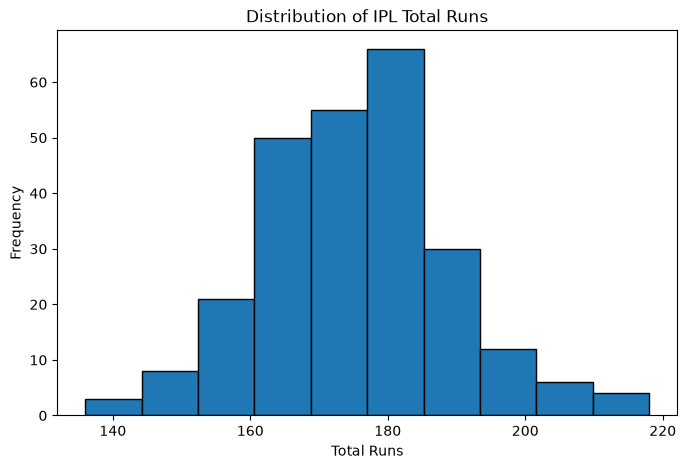

In [65]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
plt.figure(figsize=(8,5))

plt.hist(df["Total_Runs"], bins=10, edgecolor="black")

plt.title("Distribution of IPL Total Runs")
plt.xlabel("Total Runs")
plt.ylabel("Frequency")

plt.show()

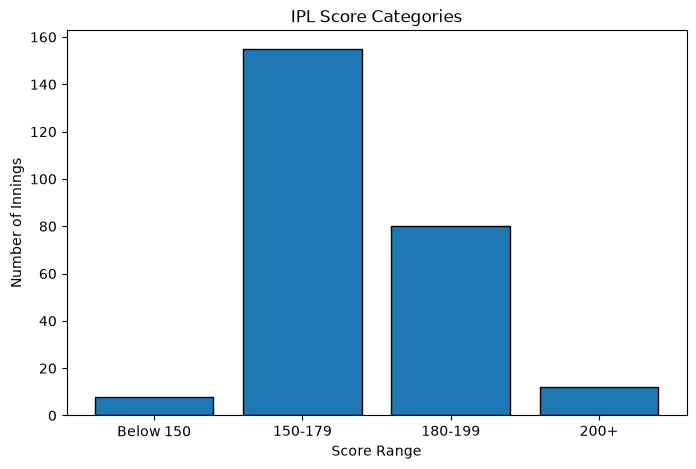

In [66]:
score_categories = [
    len(df[df["Total_Runs"] < 150]),
    len(df[(df["Total_Runs"] >= 150) & (df["Total_Runs"] < 180)]),
    len(df[(df["Total_Runs"] >= 180) & (df["Total_Runs"] < 200)]),
    len(df[df["Total_Runs"] >= 200])
]

labels = ["Below 150", "150-179", "180-199", "200+"]

plt.figure(figsize=(8,5))

plt.bar(labels, score_categories, edgecolor="black")

plt.title("IPL Score Categories")
plt.xlabel("Score Range")
plt.ylabel("Number of Innings")

plt.show()

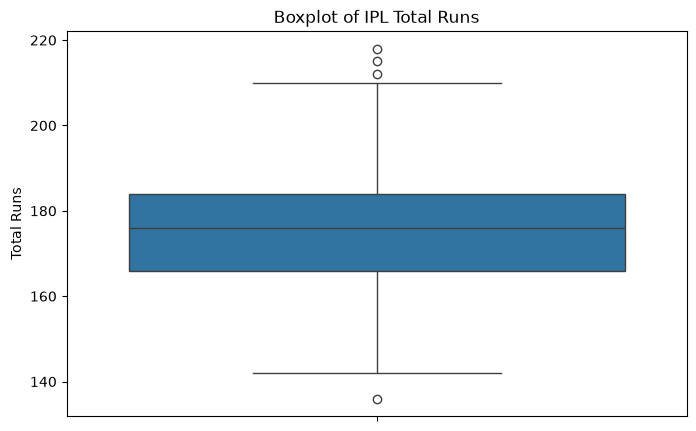

In [67]:
plt.figure(figsize=(8,5))

sns.boxplot(y=df["Total_Runs"])

plt.title("Boxplot of IPL Total Runs")
plt.ylabel("Total Runs")

plt.show()

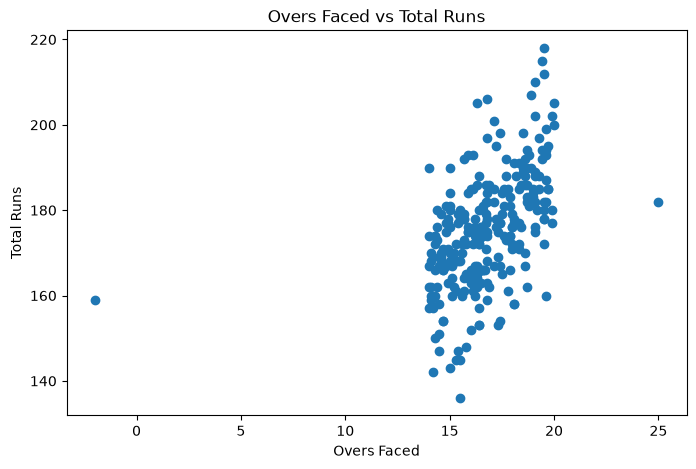

In [68]:
plt.figure(figsize=(8,5))

plt.scatter(df["Overs_Faced"], df["Total_Runs"])

plt.title("Overs Faced vs Total Runs")
plt.xlabel("Overs Faced")
plt.ylabel("Total Runs")

plt.show()

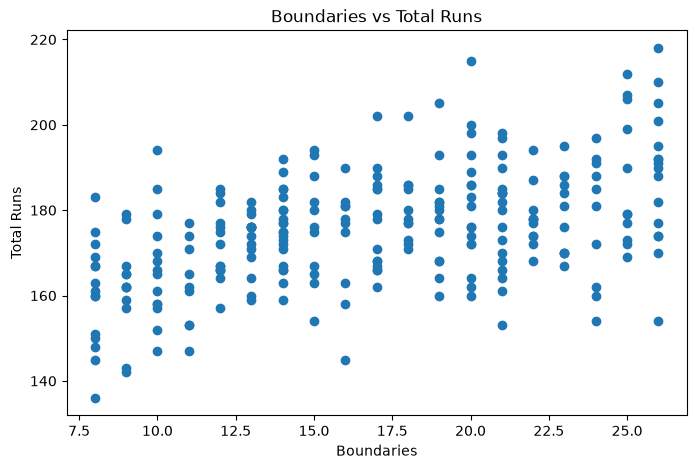

In [70]:
plt.figure(figsize=(8,5))

plt.scatter(df["Boundaries"], df["Total_Runs"])

plt.title("Boundaries vs Total Runs")
plt.xlabel("Boundaries")
plt.ylabel("Total Runs")

plt.show()

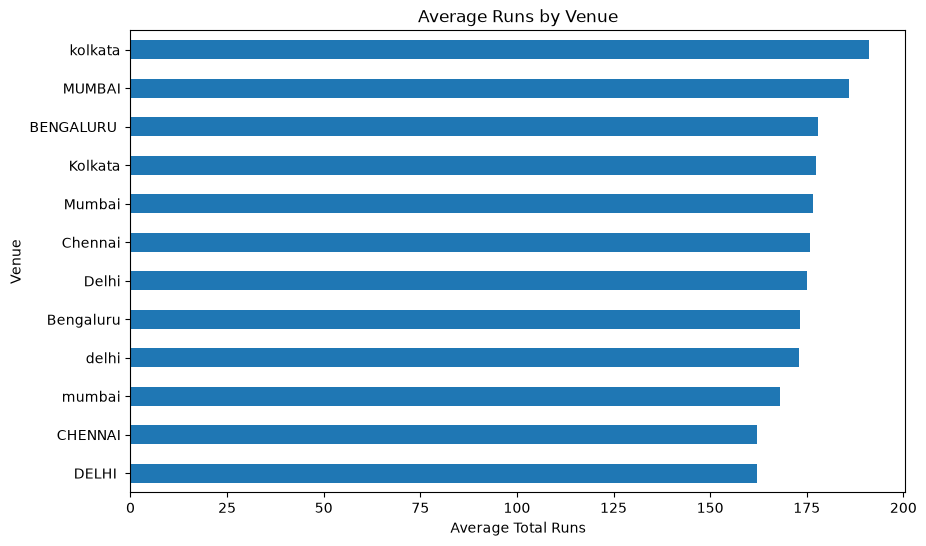

In [71]:
venue_analysis = df.groupby("Venue")["Total_Runs"].mean()

plt.figure(figsize=(10,6))

venue_analysis.sort_values().plot(kind="barh")

plt.title("Average Runs by Venue")
plt.xlabel("Average Total Runs")
plt.ylabel("Venue")

plt.show()

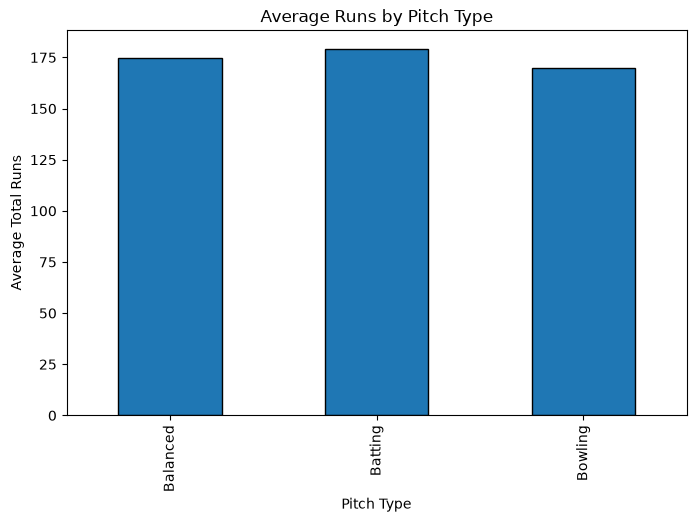

In [72]:
pitch_analysis = df.groupby("Pitch_Type")["Total_Runs"].mean()

plt.figure(figsize=(8,5))

pitch_analysis.plot(kind="bar", edgecolor="black")

plt.title("Average Runs by Pitch Type")
plt.xlabel("Pitch Type")
plt.ylabel("Average Total Runs")

plt.show()

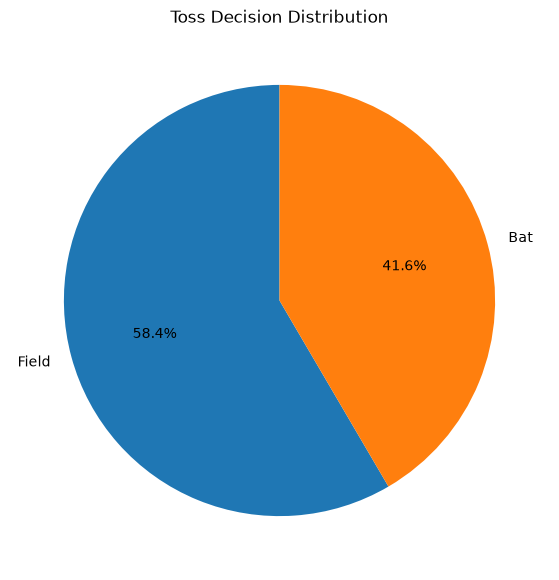

In [73]:
toss_counts = df["Toss_Decision"].value_counts()

plt.figure(figsize=(7,7))

plt.pie(
    toss_counts,
    labels=toss_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Toss Decision Distribution")

plt.show()

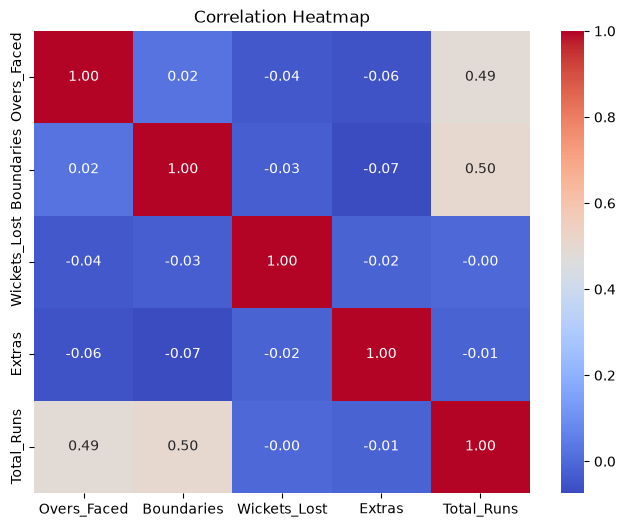

In [74]:
corr = df[[
    "Overs_Faced",
    "Boundaries",
    "Wickets_Lost",
    "Extras",
    "Total_Runs"
]].corr()

plt.figure(figsize=(8,6))

sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".2f"
)

plt.title("Correlation Heatmap")

plt.show()

Text(0, 0.5, 'Count')

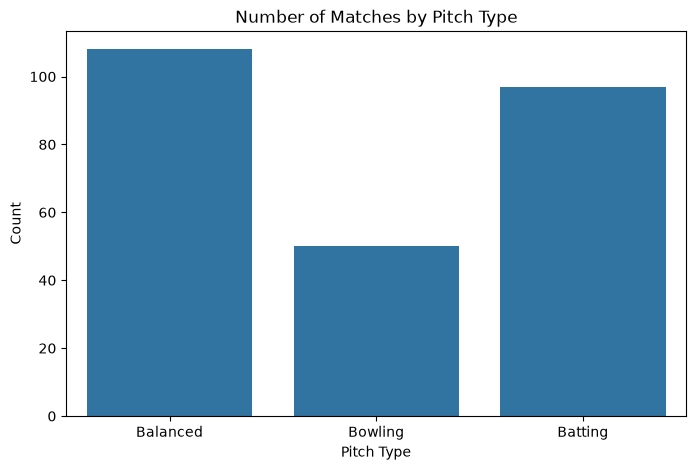

In [75]:
plt.figure(figsize=(8,5))

sns.countplot(x="Pitch_Type", data=df)

plt.title("Number of Matches by Pitch Type")
plt.xlabel("Pitch Type")
plt.ylabel("Count")

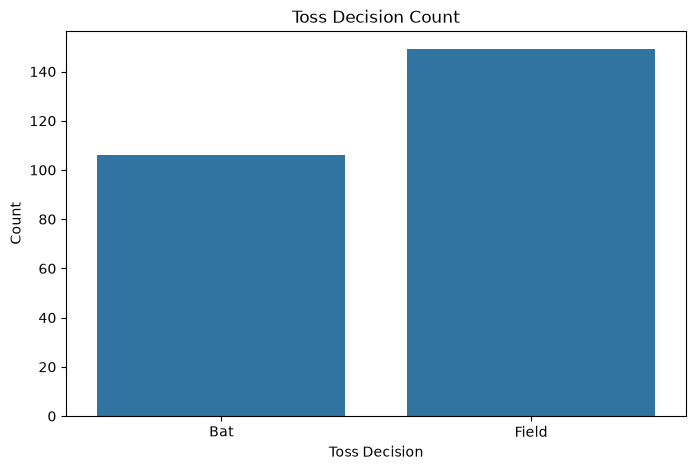

In [76]:
plt.figure(figsize=(8,5))

sns.countplot(x="Toss_Decision", data=df)

plt.title("Toss Decision Count")
plt.xlabel("Toss Decision")
plt.ylabel("Count")

plt.show()

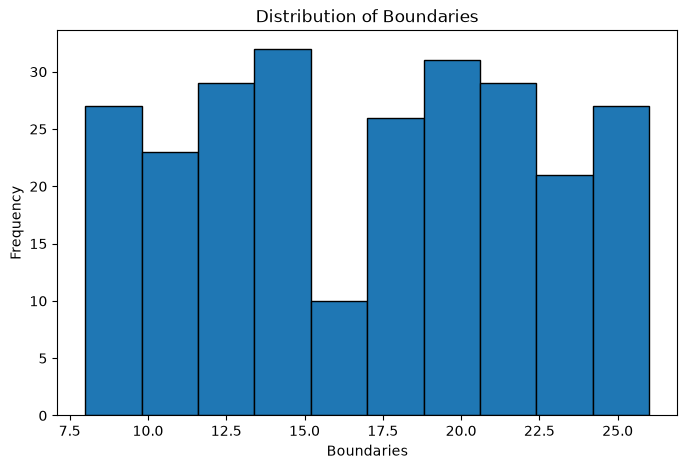

In [77]:
plt.figure(figsize=(8,5))

plt.hist(df["Boundaries"], bins=10, edgecolor="black")

plt.title("Distribution of Boundaries")
plt.xlabel("Boundaries")
plt.ylabel("Frequency")

plt.show()

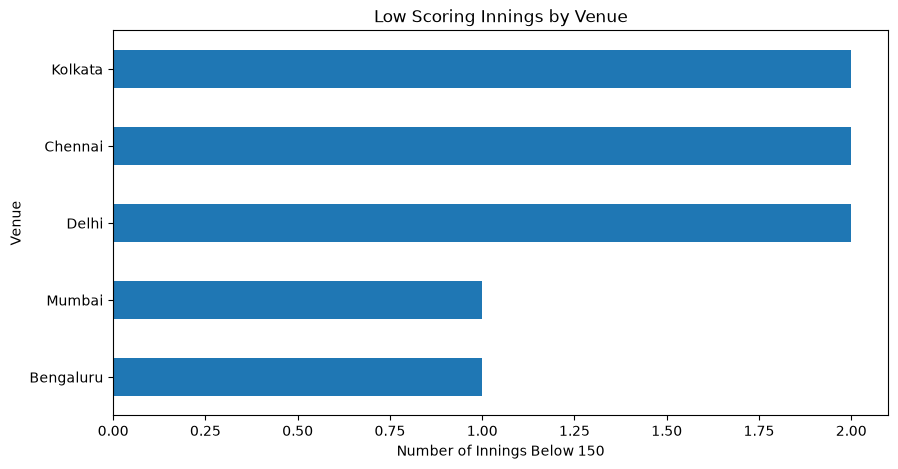

In [78]:
low_scoring = df[df["Total_Runs"] < 150]

low_venue = low_scoring.groupby("Venue")["Total_Runs"].count()

plt.figure(figsize=(10,5))

low_venue.sort_values().plot(kind="barh")

plt.title("Low Scoring Innings by Venue")
plt.xlabel("Number of Innings Below 150")
plt.ylabel("Venue")

plt.show()

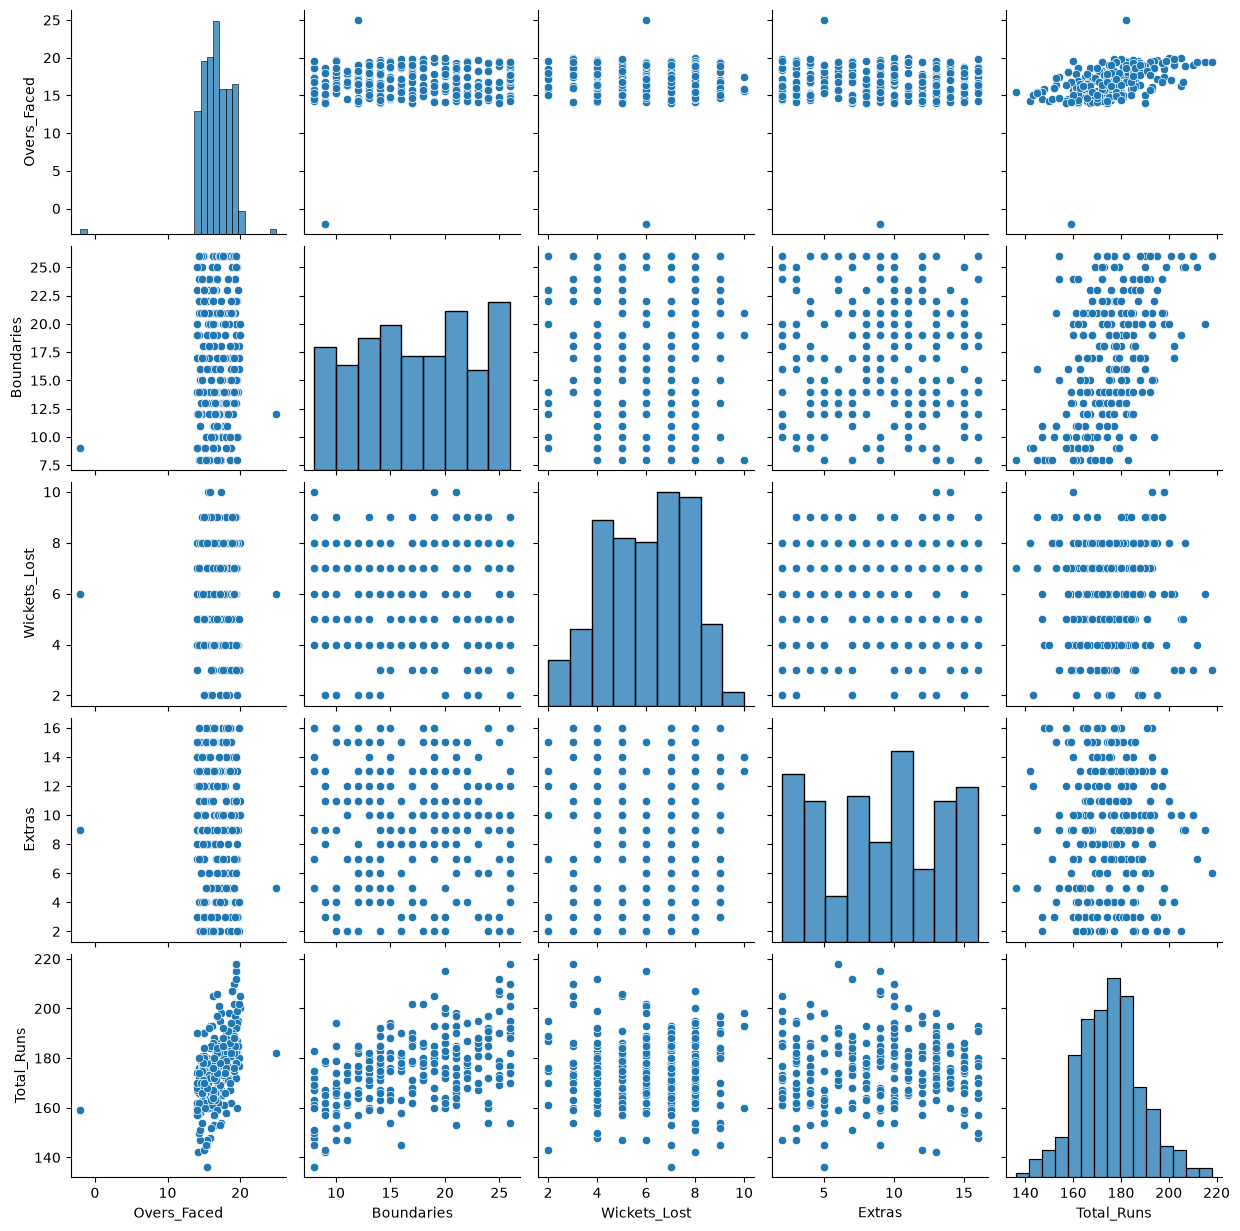

In [79]:
sns.pairplot(df[[
    "Overs_Faced",
    "Boundaries",
    "Wickets_Lost",
    "Extras",
    "Total_Runs"
]])

plt.show()

In [58]:
df.to_csv("../Data/Processed_Data/ipl_data.csv", index=False)
print("Saved cleaned file with", len(df),"rows")

Saved cleaned file with 255 rows
